# TD 4: Comparison test of two means from two independent samples

Christelle Gonindard & Matthias Grenié

**Session objective:
Understand the concept of a test for comparing two independent samples.
<=>
1 quantitative variable and 1 qualitative variable (with two modalities)**

It's important to realize that, in statistics, the choice of test is crucial and meets
conditions. In this section, we present you with a number of possible tests
to compare the numerical values (quantitative variable) of two independent samples
(representing the qualitative variable)
1. if the numbers in the two groups are >= 30: we apply the parametric Student's t test
2. if the size of one or both groups is < 30, there are two possibilities:
    - if data follow a normal distribution and variances between groups are equal: Student's t test
    - if one of the above conditions is not met: Mann-Whitney test (non-parametric).

## 1. Parametric Student's t-test 

A clinician evaluates the intensity of depression on the Hamilton scale, which ranges from 0 (not depressed) to
56 (very depressed), in 100 patients suffering from a Major Depressive Episode (MDE).
We want to know whether acupuncture improves the course of depression. To this end, 100 patients
with the same depressive state (same Hamilton score) were divided into 2 groups of 50 by drawing lots.
by lot. Group I received pharmacological treatment only, while Group II received pharmacological treatment combined with acupuncture.
pharmacological treatment combined with acupuncture.
The dataset contains the following variables:
- `hamilton_g1`: Hamilton scores, after 8 months of treatment, for patients of group I;
- `hamilton_g2`: Hamilton scores, after 8 months of treatment, for patients of group II;
- `urbanization_g1`: level of urbanization in which patients live (A: rural, B: moderate urbanization, C: highly urbanized) for patients of group I;
- `urbanization_g2`: level of urbanization in which patients live (A: rural, B: moderate urbanization, C: highly urbanized) for patients of group II;
- `age_g1`: patients' age in years for group I;
- `age_g2`: patients' age in years for group II;
- `weight_g1`: patients' weight in kilograms for group I;
- `weight_g2`: patients' weight in kilograms for group II;
- `sex_g1`: patients' gender in group I;
- `sex_g2`: patients' gender in group II.

The data is contained in the text file `data_depression.txt` in the `data/` directory, whose full path is `data/data_depression.txt`.

Data are read using R's `read.table()` function:

In [1]:
# Read data
depression = read.table("data/data_depression.txt", header = TRUE)

# Display the beginning of the data file contents 
head(depression)

,hamilton_g1,hamilton_g2,urbanization_g1,urbanization_g2,age_g1,age_g2,weight_g1,weight_g2,sex_g1,sex_g2
,<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>
1,43,25,B,B,57,48,74,93,F,H
2,29,29,A,B,37,41,95,92,H,H
3,34,18,A,A,7,30,84,86,H,H
4,39,23,A,A,37,41,104,81,H,H
5,40,24,B,A,15,30,92,74,H,F
6,41,25,B,B,45,45,85,98,H,H


**Objective:**

We are interested in the average Hamilton scores between group 1 women
and group 2 to determine whether acupuncture improves the course of depression.
of depression

### 1.2. Principle of Student's t test

We will therefore perform a comparison of means test for independent data, i.e. a Student's t-test.

The principle of this test is simple: it checks whether the difference between the two means is
far enough from 0 with a certain risk of error $\alpha$ for the two means to be considered
be considered different.

The test therefore computes the difference between $\mu _1$ and $\mu _2$ and divides by their standard deviations $S_1$ and $S_2$:

$$ t = \frac{\mu_1-\mu_2}{\sqrt{\frac{S_1 ^2}{n_1} + \frac{S_2 ^2}{n_2}}}$$.


### 1.3. Data description

Before starting an analysis, it is important to present and check the data:
- Extraction of two samples
- sample size
- statistical summary

In [2]:
# Extraction of both samples
w1 = depression[depression$sex_g1 == "F", "hamilton_g1"]
w2 = depression[depression$sex_g2 == "F", "hamilton_g2"]

# Sample size
length(w1)
length(w2)


# Statistical summary
summary(w1)
summary(w2)

[1] 11

[1] 5

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  37.00   39.00   42.00   41.64   43.50   47.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   18.0    23.0    24.0    24.8    26.0    33.0 

**Comment:**

It seems that women in group II show lower depression scores than the ones in group I.

### 1.4. Application conditions

Before applying the Student's t-test, we need to check the conditions of application:
- If the sample sizes are large ($n_1 \geq 30$ and $n_2 \geq 30$): no conditions apply.
- If the size of at least one of the samples is less than 30, then :
    - the data from both samples follow a normal distribution
    - the variances of the two samples are equal

We are dealing with small samples, so we need to check the conditions of application.

#### 1.4.1 Data normality

We will apply Shapiro's test:

Complete the hypotheses tested:

H0 : The scores follow a normal distribution 

H1 : The scores do not follow a normal distribution

In [7]:
# Shapiro's test
shapiro.test(w1)
shapiro.test(w2)


	Shapiro-Wilk normality test

data:  w1
W = 0.94764, p-value = 0.614



	Shapiro-Wilk normality test

data:  w2
W = 0.96258, p-value = 0.8258


**Conclusion** : 

In both cases we observe p >>> alpha = 0.05, so we can't reject H0, and thus w1 and w2 follow a normal distribution.

Plot the fit of the sample quantiles to the theoretical quantiles of the Normal distribution.

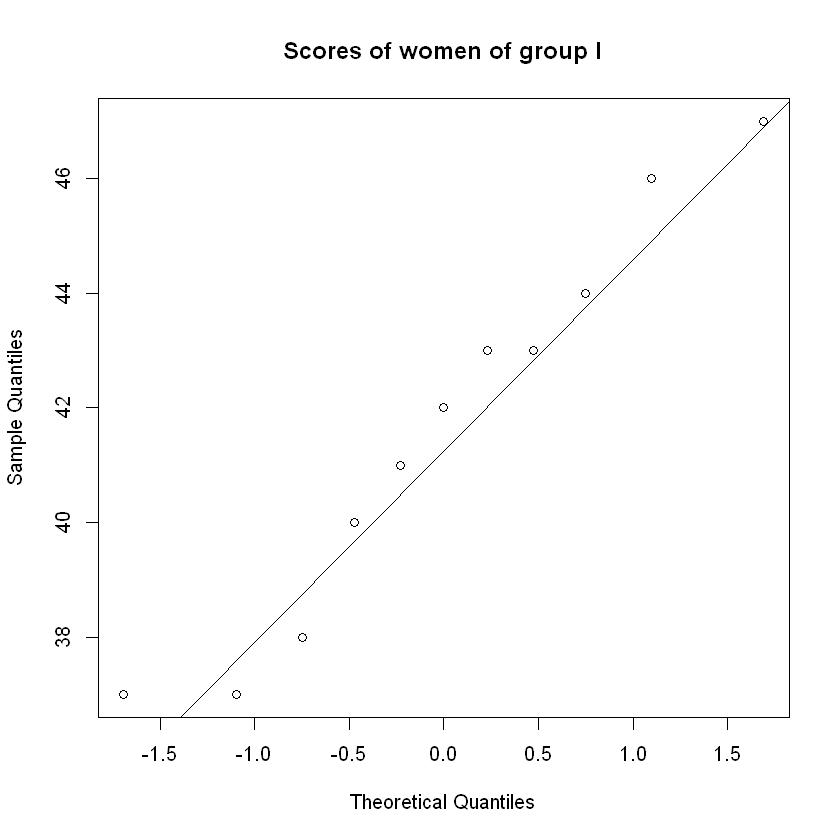

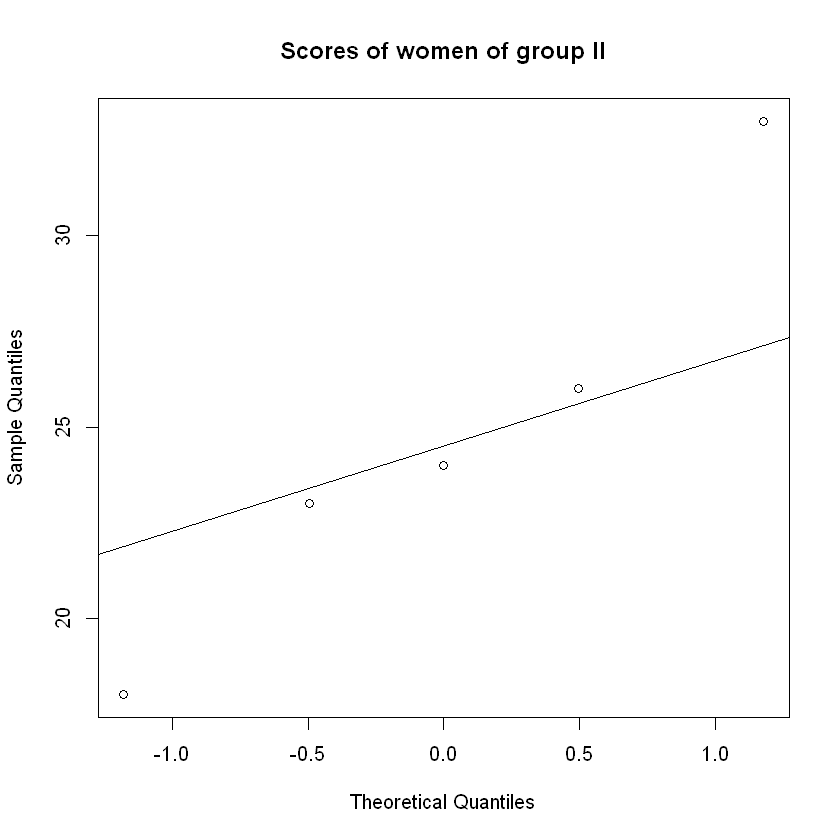

In [8]:
qqnorm(w1, main = "Scores of women of group I")
qqline(w1)

qqnorm(w2, main = "Scores of women of group II")
qqline(w2)


**Comment:**

Both follow a normal distribution we can proceed to check the rest of the assumptions

#### 1.4.2 Equality of variances

The equality of variances is verified by the Fisher-Snedecor F-statistic test.

The principle of this test is simple: simply check whether the ratio of the largest variance to the smallest variance is sufficiently greater than one for a given risk.
smallest variance is sufficiently greater than 1 with a certain risk of error $\alpha$ for the two variances to be
for the two variances to be considered different:

$$ F = \frac{sigma ^2_{max}}{sigma ^2_{min}}$$

You can perform the test through the function `var.test()`, it takes the two samples as the two first arguments.


Hypotheses of the Fisher's variance test:

H0 : The variances of the two samples are equal

H1 : The variances of the two samples are different

In [9]:
# Perform the variance test
var.test(w1, w2)


	F test to compare two variances

data:  w1 and w2
F = 0.39241, num df = 10, denom df = 4, p-value = 0.2099
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.04437067 1.75341717
sample estimates:
ratio of variances 
         0.3924089 


**Conclusion**:

We observe p = 0.21 > alpha = 0.05, so we can't reject H0, and the variances of the two samples are equal.

### 1.5. Performing the Student's t-test


**Reminder of the goal of the session:**

We are interested in the average Hamilton scores between women of group 1 and group 2 to determine whether acupuncture improves the course of depression.

Specify hypotheses:

H0 : w1 = w2

H1 : w1 ≠ w2

Perform Student's t-test

In [10]:
# Student's t-test
t.test(w1, w2, var.equal = TRUE)


	Two Sample t-test

data:  w1 and w2
t = 7.6134, df = 14, p-value = 2.426e-06
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 12.09338 21.57935
sample estimates:
mean of x mean of y 
 41.63636  24.80000 


**Conclusion** :

We observe p = 2.43⋅10⁻⁶ <<< alpha = 0.05, so we reject H0, and thus the means of women in group I and II are different.

## 2. Test for comparing two samples when the conditions for applying Student's test are not met: Mann-Whitney test

### 2.1 Background: Why non-parametric tests?

These tests do not require any binding assumptions about the distributions. and do not require any
no application conditions or assumptions of any kind, e.g. :

- no need to make assumptions about the shape of the distributions (normality, etc.)
- no need to estimate associated parameters (e.g. the mean if the distribution were Gaussian, etc.).

Their scope of application is therefore broader than parametric tests.

**Non-parametric tests are also suitable for ordinal data**. In many cases
the data available are orders of magnitude, it is difficult to give a clear interpretation
interpretation of the value. In this case, the most important thing is the relative position of the observations,
their ordering.

*Example:*
1. when data are expressed as degrees of preference (e.g.: very dissatisfied, dissatisfied, indifferent, satisfied, very satisfied), with few possible values
2. when data are categorical

**Robustness against outliers**: the transformation of data into ranks
introduces a very valuable property, as statistics associated with ranks are far less
sensitive to outliers than parametric statistics.

*In fact, the presence of an atypical point very often distorts the mean, which plays a central role in parametric tests.
in parametric tests. If the atypical point corresponds to a very large value, deviating sharply from the others
from the others, the mean is “pulled” upwards, skewing all subsequent calculations.
With ranks, only the information “the point corresponds to the highest value” is considered,
with no order of magnitude, the harmful role of atypical observations is diminished.

### 2.2 Test principle 

The Mann-Whitney test uses the **ranks** of the data, not the data itself,
i.e. the order in which the observations from the two samples appear together:

1. the test assigns a rank to the values of the two samples.
2. From this, the average rank for each sample is calculated. The principle being that if there is no difference between the two samples (H0) then the mean ranks should be equal (Mann-Whitney U statistic).

Example: we want to compare two brands of anti-pollution filters, **company A** and **company B** as company A pretends its filter is better. The filters are scored based on their efficiency from 0 to 100 (with 100 being most efficient). We then rank all observations **together**.

|          Variable |    |    |      |      |    |    |    |    |    |    |    |    |    |    |    |    |    |    |    |    |    |
|-------------------|----|----|------|------|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|
|           Company |  A |  A |    A |    A |  A |  A |  A |  A |  A |  A |  B |  B |  B |  B |  B |  B |  B |  B |  B |  B |  B |
|        Efficiency | 72 | 79 |   92 |   92 | 70 | 95 | 82 | 80 | 74 | 86 | 78 | 66 | 65 | 84 | 69 | 73 | 71 | 75 | 68 | 90 | 76 |
| Rank (increasing) |  7 | 13 | 19.5 | 19.5 |  5 | 72 | 15 | 14 |  9 | 17 | 12 |  2 |  1 | 16 |  4 |  8 |  6 | 10 |  3 | 18 | 11 |

Sum of ranks of company A: $S_1 = 140$  
Average rank of company A: $\hat{r_1} = \frac{S_1}{n_1} = \frac{140}{10} = 14$

Sum of ranks of company B: $S_2 = 91$  
Average rank of company B: $\hat{r_2} = \frac{S_2}{n_2} = \frac{91}{11} = 8.27$


### 3.3 Example: Comparison of 2 diets

Two groups of 10 rabbits each fed a cholesterol-enriched diet were subjected to
2 different treatments (to combat cholesterol). Are the results different between
the two diets at the 2% threshold?

Cholesterol levels are recorded in dg/l. 

The data are contained in the text file in the `TD04_data_rabbit.txt` in the `data/` folder.

1. Read the data


In [11]:
# Read data
rabbit = read.table("data/TD04_data_rabbit.txt", header = TRUE)

# Display start of data file contents
head(rabbit)

,x,y
,<int>,<int>
1,16,18
2,13,22
3,28,33
4,26,334
5,13,19
6,28,32


2. Describing and presenting data

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  13.00   16.25   25.50   22.50   28.00   30.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  18.00   23.25   31.50   58.10   32.75  334.00 

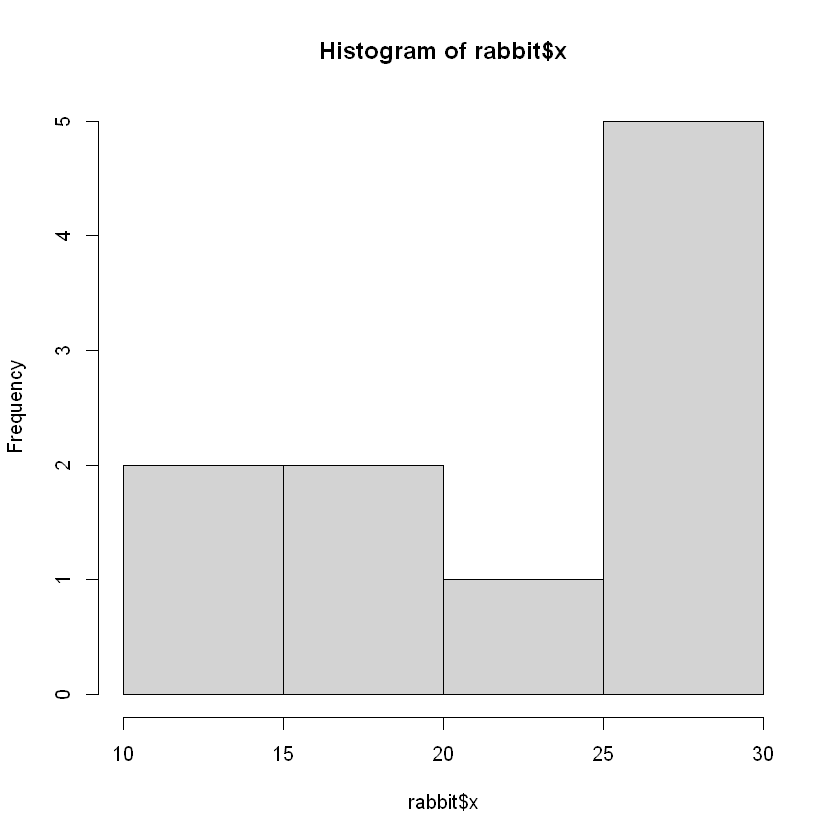

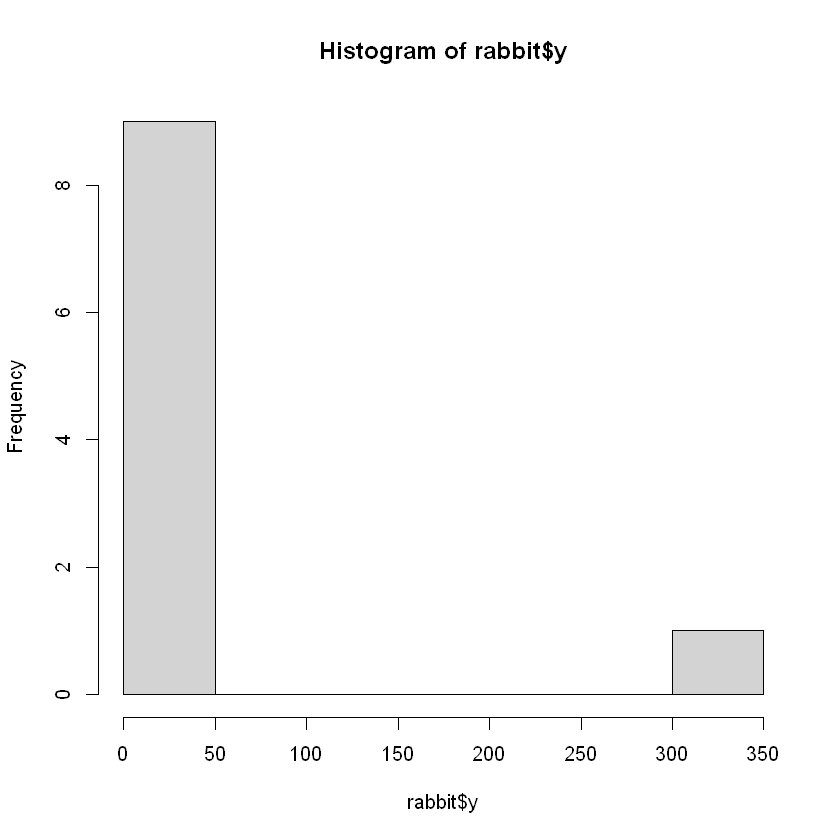

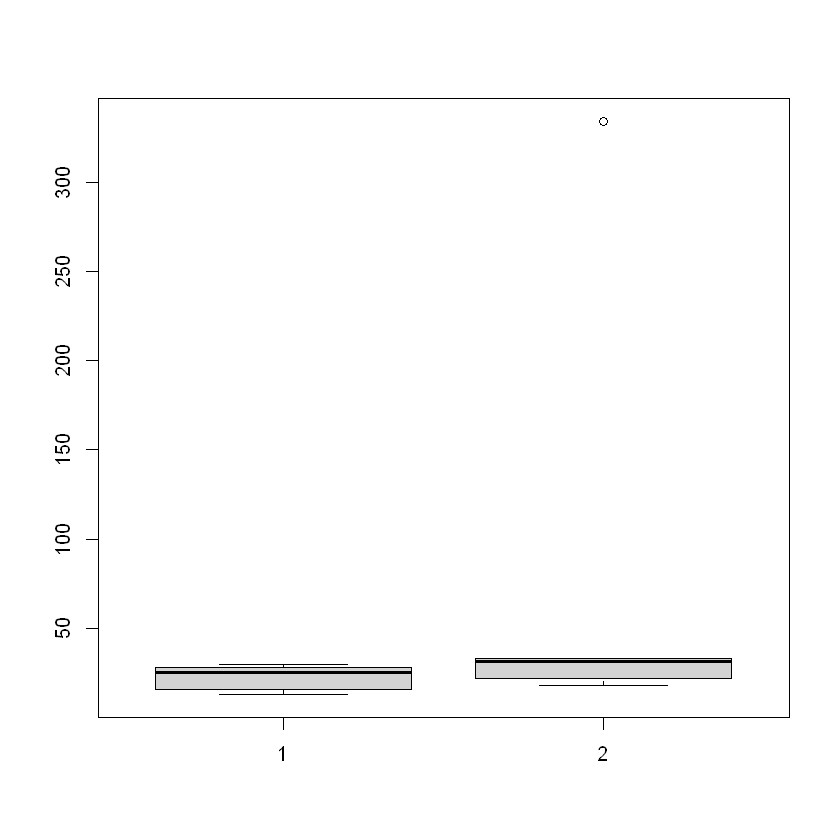

In [14]:
summary(rabbit$x)
summary(rabbit$y)

hist(rabbit$x)
hist(rabbit$y)

boxplot(rabbit$x, rabbit$y)

**Comment:**

Treatment y seems to show greater average cholesterol with one individual being a strong outlier.

2. Application conditions:

In [16]:
length(rabbit$x)
length(rabbit$y)

# n = 10 -> need to check normality
# Shapiro test
# H0: cholesterol follows a normal distribution
# H1: it doesn't follow a normal distribution
shapiro.test(rabbit$x)
shapiro.test(rabbit$y)

# For both tests we observe p < alpha = 0.05, so we reject H0, which means that the cholesterol doesn't follow a Normal distribution

[1] 10

[1] 10


	Shapiro-Wilk normality test

data:  rabbit$x
W = 0.83676, p-value = 0.04035



	Shapiro-Wilk normality test

data:  rabbit$y
W = 0.42042, p-value = 4.298e-07


**Conclude**:  
For both tests we observe p < alpha = 0.05, so we reject H0, which means that the cholesterol doesn't follow a Normal distribution.  
So we can't perform a t-test.

3. Assumptions of the Mann-Whitney test

If the application conditions of a Student's t-test aren't met it's still possible to compare the mean of two independent samples through the Mann-Whitney test.

We want to check whether diets have a different effect, so we're going to do a two-tailed test
test:

Specify hypotheses H0 and H1

H0 : The means of x and y are equal

H1 : The means of x and y are different

4. Performing the test

To perform it you can use the `wilcox.test()` function with the two samples as the two first arguments.

In [17]:
wilcox.test(rabbit$x, rabbit$y)

Warning message in wilcox.test.default(rabbit$x, rabbit$y):
"impossible de calculer la p-value exacte avec des ex-aequos"



	Wilcoxon rank sum test with continuity correction

data:  rabbit$x and rabbit$y
W = 22, p-value = 0.03735
alternative hypothesis: true location shift is not equal to 0


**Conclusion**:  
We see p = 0.037 < alpha = 0.05, so we reject H0, which means that x and y have different means.

**Note: for the Mann-Whitney test, use the `wilcox.test()` function,
It allows you to perform both the Mann-Whitney test and the Wilcoxon test
test, as we'll see below**.

## 3. Exercises application

## Exercise 1

The diuretic activity of a new drug and that of product X with known diuretic activity are compared in mice.
activity are compared in mice. Twenty mice of the same age are divided into two groups
of 10. One group receives the new drug and the other group receives product X.
- **Question 1**: Which of the three methods shown below is the most appropriate for forming the two groups? Justify your answer.
    1. 1st method: the 20 mice are randomly divided into 2 groups of 10 mice each.
    2. 2nd method: all 20 mice are placed in the same cage; the experimenter catches the first 10 mice to come out of the cage and places them in another cage.
    3. 3rd method: all mice are weighed to create 2 groups of as even weight as possible. One group is made up of the 10 lowest-weight mice; the other is made up of the 10 highest-weight mice.
- **Question 2**: Two protocol designs are possible. The known treatment can be a placebo or a reference diuretic treatment. Discuss the choice of each of these two strategies.
- **Question 3**: A fixed dose of 20mg of the new drug or product X is administered to each animal. The two groups of 10 mice are placed in metabolism cages that allow easy measurement of urine volume. 

The results are contained in the `TD04_exercise1.txt` file in the `data/` folder. Analyze these data in order to answer the question:  
*Is the diuresis observed with the new drug significantly greater than that observed with product X, at the 5% risk, at the 1% risk?*

**Question 1**:  

Best method is the 1st one as it randomly assigns the individuals to the two groups. Otherwise we risk artificially observing differences between groups not because of the drug but because of either their initial behavior (shy vs. not in the 2nd method) or their weights (3rd method).

**Question 2**:

If we test against placebo it means we're testing to see if our treatment has an effect at all whereas if we treat with reference diuretic we're testing to what extent our treatment is better than the current practice.

**Question 3**:

In [22]:
# Load data
mice = read.table("data/TD04_exercise1.txt", header = TRUE)
head(mice)

# We want to perform a one-sided Student's t-test with the following hypotheses:
# H0: The two products have the same diuretic activity
# H1: The new drug has a greater activity that product X

# First let's check the assumptions:
# 1. Sample size
# 2. Equality of variance

## 1. Sample size
length(mice$product_x)
length(mice$new_medicine)

# n < 30, so we need to check for normality
# H0: Data are following a normal distribution
# H1: Data aren't following a normal distribution
shapiro.test(mice$product_x)
shapiro.test(mice$new_medicine)
# For both we have p >>> alpha = 0.05 or even alpha = 0.01, so they both follow a normal distribution

## 2. Equality of variance
# Fisher's test
# H0: Both samples have the same variance
# H1: They have different variances
var.test(mice$product_x, mice$new_medicine)
# >e have p = 0.4 >>> alpha = 0.05 and alpha = 0.01, so they have the same variance
# => We can proceed to the one-sided t-test

t.test(mice$new_medicine, mice$product_x, alternative = "greater")

# We observe p = 0.03 which is greater than alpha = 0.05 but lower than alpha = 0.01, so we can say that at 5% the new drug show greater diuresis than product X but not at 1%.

,product_x,new_medicine
,<dbl>,<dbl>
1,17.09903,23.54705
2,16.06864,23.40862
3,12.25383,23.55035
4,14.09870,17.86841
5,20.10046,21.40830
6,16.25313,16.51751


[1] 10

[1] 10


	Shapiro-Wilk normality test

data:  mice$product_x
W = 0.96599, p-value = 0.8514



	Shapiro-Wilk normality test

data:  mice$new_medicine
W = 0.87496, p-value = 0.1141



	F test to compare two variances

data:  mice$product_x and mice$new_medicine
F = 1.7813, num df = 9, denom df = 9, p-value = 0.4027
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.4424553 7.1715942
sample estimates:
ratio of variances 
          1.781323 



	Welch Two Sample t-test

data:  mice$new_medicine and mice$product_x
t = 2.0101, df = 16.683, p-value = 0.03044
alternative hypothesis: true difference in means is greater than 0
95 percent confidence interval:
 0.3881949       Inf
sample estimates:
mean of x mean of y 
 20.86216  17.95739 


## Exercise 2 

To determine the iodine value of 2 oils *O1* and *O2*, 9 and 10 analyses were carried out respectively.  
The iodine values are contained in the file `TD04_exercise2.txt` in the `data/` folder.

Answer the following question:  
*Does the iodine value differ for the 2 oils at the 5% threshold?*

In [28]:
oils = read.table("data/TD04_exercise2.txt", header = TRUE)
head(oils)

summary(oils)
# It seems O2 contains slightly more iodine according to the summary stats

length(oils$O1)

# There are 10 observations so we need to check normality
# We perform a Shapiro-Wilk test with the same asusumptions as always
shapiro.test(oils$O1)
shapiro.test(oils$O2)
# => in both cases we observe p >>> alpha, so we can't reject H0, so both show a normal distribution

# Let's now test the equality of variances
# H0: variance of O1 = variance of O2
# H1: variance of O1 ≠ variance of O2
var.test(oils$O1, oils$O2)
# We see p = 0.2 > alpha = 0.05, so we can't reject H0, so O1 and O2 show equal variances
# => we can proceed to the t-test!

t.test(oils$O1, oils$O2, var.equal = TRUE)

# We see p = 0.009 <<< alpha = 0.05, so we reject H0, which means that the iodine value differs between the oils

,O1,O2
,<dbl>,<dbl>
1,65.5,68.7
2,65.3,66.7
3,67.1,69.3
4,66.4,67.8
5,67.1,73.7
6,68.4,76.4


       O1              O2       
 Min.   :65.30   Min.   :66.70  
 1st Qu.:66.40   1st Qu.:68.85  
 Median :67.10   Median :70.75  
 Mean   :67.48   Mean   :71.04  
 3rd Qu.:68.40   3rd Qu.:73.30  
 Max.   :71.50   Max.   :76.40  
 NA's   :1                      

[1] 10


	Shapiro-Wilk normality test

data:  oils$O1
W = 0.91046, p-value = 0.3191



	Shapiro-Wilk normality test

data:  oils$O2
W = 0.95846, p-value = 0.7682



	F test to compare two variances

data:  oils$O1 and oils$O2
F = 0.39043, num df = 8, denom df = 9, p-value = 0.2
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.09518138 1.70119357
sample estimates:
ratio of variances 
         0.3904298 



	Two Sample t-test

data:  oils$O1 and oils$O2
t = -2.9353, df = 17, p-value = 0.009244
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -6.122677 -1.001767
sample estimates:
mean of x mean of y 
 67.47778  71.04000 
